In [67]:
# =========================================
# IMPORT LIBRARIES
# =========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Set seaborn style for better visuals
sns.set_style("whitegrid")
sns.set_context("talk")
df = pd.read_excel("Barclays Financial Transactional Data.xlsx")

df.head()
df.info()
df.info()
df.describe()
df.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   TransactionID      800 non-null    int64  
 1   CustomerID         800 non-null    object 
 2   AccountID          800 non-null    object 
 3   AccountType        800 non-null    object 
 4   TransactionType    800 non-null    object 
 5   Product            800 non-null    object 
 6   Firm               800 non-null    object 
 7   Region             800 non-null    object 
 8   Manager            800 non-null    object 
 9   TransactionDate    800 non-null    object 
 10  TransactionAmount  800 non-null    float64
 11  AccountBalance     800 non-null    float64
 12  RiskScore          800 non-null    float64
 13  CreditRating       800 non-null    int64  
 14  TenureMonths       800 non-null    int64  
dtypes: float64(3), int64(3), object(9)
memory usage: 93.9+ KB
<class 'pandas.c

TransactionID        0
CustomerID           0
AccountID            0
AccountType          0
TransactionType      0
Product              0
Firm                 0
Region               0
Manager              0
TransactionDate      0
TransactionAmount    0
AccountBalance       0
RiskScore            0
CreditRating         0
TenureMonths         0
dtype: int64

In [68]:
df = pd.read_excel("Barclays Financial Transactional Data.xlsx")

df.head()

,TransactionID,CustomerID,AccountID,AccountType,TransactionType,Product,Firm,Region,Manager,TransactionDate,TransactionAmount,AccountBalance,RiskScore,CreditRating,TenureMonths
0,118,CUST3810,ACC49774,Savings,Deposit,Credit Card,Firm D,West,Manager 4,2024-08-01 00:00:00,20664.409820,88483.42208,0.483333,522,29
1,102,CUST3109,ACC96277,Savings,Deposit,Mutual Fund,Firm B,North,Manager 4,17-12-2023,94924.359120,56670.15864,0.788989,686,130
2,151,CUST2626,ACC21429,Credit,Payment,Personal Loan,Firm C,West,Manager 1,22-05-2024,-7871.160407,84968.05587,0.547782,618,157
3,57,CUST3725,ACC48501,Loan,Withdrawal,Credit Card,Firm A,East,Manager 4,24-12-2023,24979.808160,115196.96420,0.125587,803,155
4,113,CUST4258,ACC11285,Loan,Transfer,Home Loan,Firm A,West,Manager 4,15-01-2023,72890.748550,111602.76610,1.048787,657,68


In [69]:
df.info()
df.describe()
df.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   TransactionID      800 non-null    int64  
 1   CustomerID         800 non-null    object 
 2   AccountID          800 non-null    object 
 3   AccountType        800 non-null    object 
 4   TransactionType    800 non-null    object 
 5   Product            800 non-null    object 
 6   Firm               800 non-null    object 
 7   Region             800 non-null    object 
 8   Manager            800 non-null    object 
 9   TransactionDate    800 non-null    object 
 10  TransactionAmount  800 non-null    float64
 11  AccountBalance     800 non-null    float64
 12  RiskScore          800 non-null    float64
 13  CreditRating       800 non-null    int64  
 14  TenureMonths       800 non-null    int64  
dtypes: float64(3), int64(3), object(9)
memory usage: 93.9+ KB


TransactionID        0
CustomerID           0
AccountID            0
AccountType          0
TransactionType      0
Product              0
Firm                 0
Region               0
Manager              0
TransactionDate      0
TransactionAmount    0
AccountBalance       0
RiskScore            0
CreditRating         0
TenureMonths         0
dtype: int64

In [70]:


# =========================================
# TASK 1: DATA CLEANING AND FORMATTING
# =========================================

# 1. Convert TransactionDate to datetime format
df['TransactionDate'] = pd.to_datetime(df['TransactionDate'])

# 2. Ensure TransactionAmount is numeric
# (handles any non-numeric values safely)
df['TransactionAmount'] = pd.to_numeric(df['TransactionAmount'], errors='coerce')

# 3. Standardize categorical columns (convert to lowercase)
df['TransactionType'] = df['TransactionType'].str.lower()
df['AccountType'] = df['AccountType'].str.lower()

# 4. Handle missing values using forward fill (UPDATED METHOD)
df.ffill(inplace=True)

# 5. Remove duplicate records
df.drop_duplicates(inplace=True)

# 6. Final check after cleaning
print("Data after cleaning:")
print(df.info())

print("\nMissing values after cleaning:")
print(df.isnull().sum())

Data after cleaning:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   TransactionID      800 non-null    int64         
 1   CustomerID         800 non-null    object        
 2   AccountID          800 non-null    object        
 3   AccountType        800 non-null    object        
 4   TransactionType    800 non-null    object        
 5   Product            800 non-null    object        
 6   Firm               800 non-null    object        
 7   Region             800 non-null    object        
 8   Manager            800 non-null    object        
 9   TransactionDate    800 non-null    datetime64[ns]
 10  TransactionAmount  800 non-null    float64       
 11  AccountBalance     800 non-null    float64       
 12  RiskScore          800 non-null    float64       
 13  CreditRating       800 non-null    int64    

In [71]:
print("Missing Values:\n", df.isnull().sum())
print("\nDuplicates:", df.duplicated().sum())
print("\nData Types:\n", df.dtypes)

Missing Values:
 TransactionID        0
CustomerID           0
AccountID            0
AccountType          0
TransactionType      0
Product              0
Firm                 0
Region               0
Manager              0
TransactionDate      0
TransactionAmount    0
AccountBalance       0
RiskScore            0
CreditRating         0
TenureMonths         0
dtype: int64

Duplicates: 0

Data Types:
 TransactionID                 int64
CustomerID                   object
AccountID                    object
AccountType                  object
TransactionType              object
Product                      object
Firm                         object
Region                       object
Manager                      object
TransactionDate      datetime64[ns]
TransactionAmount           float64
AccountBalance              float64
RiskScore                   float64
CreditRating                  int64
TenureMonths                  int64
dtype: object


In [72]:
df.head()
df.tail()
df.sample(5)

,TransactionID,CustomerID,AccountID,AccountType,TransactionType,Product,Firm,Region,Manager,TransactionDate,TransactionAmount,AccountBalance,RiskScore,CreditRating,TenureMonths
512,163,CUST2188,ACC76597,current,payment,Personal Loan,Firm B,Central,Manager 3,2023-12-05,79844.759600,7800.507429,0.811947,305,163
694,42,CUST2871,ACC55331,loan,withdrawal,Credit Card,Firm E,North,Manager 1,2024-03-19,49688.749210,184008.258800,0.306690,466,17
275,45,CUST7493,ACC12182,current,payment,Home Loan,Firm E,Central,Manager 3,2023-02-26,70196.432590,58853.728110,0.524334,394,195
573,45,CUST7651,ACC91220,loan,deposit,Home Loan,Firm D,North,Manager 4,2024-02-21,40435.599390,147926.416500,0.155613,436,42
744,85,CUST8318,ACC33287,savings,transfer,Savings Account,Firm A,West,Manager 1,2023-08-18,3208.565062,92345.484150,0.657938,536,172


In [73]:
df.to_csv("cleaned_dataset.csv", index=False)

In [74]:
# ==============================
# TASK 1 VERIFICATION
# ==============================

print("Missing Values:\n", df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nData Types:\n", df.dtypes)

print("\nUnique Transaction Types:", df['TransactionType'].unique())

print("\nUnique Account Types:", df['AccountType'].unique())

Missing Values:
 TransactionID        0
CustomerID           0
AccountID            0
AccountType          0
TransactionType      0
Product              0
Firm                 0
Region               0
Manager              0
TransactionDate      0
TransactionAmount    0
AccountBalance       0
RiskScore            0
CreditRating         0
TenureMonths         0
dtype: int64

Duplicate Rows: 0

Data Types:
 TransactionID                 int64
CustomerID                   object
AccountID                    object
AccountType                  object
TransactionType              object
Product                      object
Firm                         object
Region                       object
Manager                      object
TransactionDate      datetime64[ns]
TransactionAmount           float64
AccountBalance              float64
RiskScore                   float64
CreditRating                  int64
TenureMonths                  int64
dtype: object

Unique Transaction Types: ['deposit' 

In [75]:
df 

,TransactionID,CustomerID,AccountID,AccountType,TransactionType,Product,Firm,Region,Manager,TransactionDate,TransactionAmount,AccountBalance,RiskScore,CreditRating,TenureMonths
0,118,CUST3810,ACC49774,savings,deposit,Credit Card,Firm D,West,Manager 4,2024-08-01,20664.409820,88483.42208,0.483333,522,29
1,102,CUST3109,ACC96277,savings,deposit,Mutual Fund,Firm B,North,Manager 4,2023-12-17,94924.359120,56670.15864,0.788989,686,130
2,151,CUST2626,ACC21429,credit,payment,Personal Loan,Firm C,West,Manager 1,2024-05-22,-7871.160407,84968.05587,0.547782,618,157
3,57,CUST3725,ACC48501,loan,withdrawal,Credit Card,Firm A,East,Manager 4,2023-12-24,24979.808160,115196.96420,0.125587,803,155
4,113,CUST4258,ACC11285,loan,transfer,Home Loan,Firm A,West,Manager 4,2023-01-15,72890.748550,111602.76610,1.048787,657,68
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
795,102,CUST9535,ACC88516,current,deposit,Mutual Fund,Firm E,North,Manager 3,2023-09-26,56158.330740,49260.11922,0.966960,371,206
796,106,CUST6937,ACC65144,savings,transfer,Mutual Fund,Firm D,East,Manager 3,2023-06-07,57508.001850,19847.81739,0.909006,748,72
797,61,CUST3725,ACC70741,loan,deposit,Mutual Fund,Firm E,North,Manager 4,2023-02-01,77193.680650,30102.94832,0.655215,438,142
798,110,CUST6350,ACC12182,credit,payment,Personal Loan,Firm A,East,Manager 1,2023-09-28,44400.426210,87156.82842,0.341699,333,144


In [76]:
df.to_excel("cleaned_dataset.xlsx", index=False)

In [77]:
# Convert to credit/debit format

df['TransactionType'] = df['TransactionType'].replace({
    'deposit': 'credit',
    'transfer': 'credit',
    'payment': 'debit',
    'withdrawal': 'debit'
})

In [78]:
df['TransactionDate'] = pd.to_datetime(df['TransactionDate'], dayfirst=True)

In [79]:
df['AccountType'] = df['AccountType'].str.lower()

In [80]:
print(df.isnull().sum())
print(df.duplicated().sum())
print(df.dtypes)
print(df['TransactionType'].unique())

TransactionID        0
CustomerID           0
AccountID            0
AccountType          0
TransactionType      0
Product              0
Firm                 0
Region               0
Manager              0
TransactionDate      0
TransactionAmount    0
AccountBalance       0
RiskScore            0
CreditRating         0
TenureMonths         0
dtype: int64
0
TransactionID                 int64
CustomerID                   object
AccountID                    object
AccountType                  object
TransactionType              object
Product                      object
Firm                         object
Region                       object
Manager                      object
TransactionDate      datetime64[ns]
TransactionAmount           float64
AccountBalance              float64
RiskScore                   float64
CreditRating                  int64
TenureMonths                  int64
dtype: object
['credit' 'debit']


In [81]:
# Save cleaned dataset as Excel file
df.to_excel("cleaned_dataset.xlsx", index=False)

In [82]:
import os
os.listdir()

['.ipynb_checkpoints',
 'Barclays Financial Transactional Data.xlsx',
 'cleaned_dataset.csv',
 'cleaned_dataset.xlsx',
 'final_cleaned_data.xlsx',
 'Financial_Risk_Analysis.ipynb']

In [83]:

# =========================================
# SUB-TASK 2.1: FEATURE ENGINEERING
# =========================================

# Extract Month and Year from TransactionDate
df['Month'] = df['TransactionDate'].dt.month
df['Year'] = df['TransactionDate'].dt.year

df[['TransactionDate','Month','Year']].head()

,TransactionDate,Month,Year
0,2024-08-01,8,2024
1,2023-12-17,12,2023
2,2024-05-22,5,2024
3,2023-12-24,12,2023
4,2023-01-15,1,2023


In [84]:
#Month and Year features were extracted to analyze transaction trends over time.

In [85]:
# =========================================
# SUB-TASK 2.2: MONTHLY TRANSACTION SUMMARY
# =========================================

# Group data by Year and Month
monthly_summary = df.groupby(['Year','Month'])['TransactionAmount'].sum()

monthly_summary

Year  Month
2023  1        3.108140e+06
      2        1.791555e+06
      3        8.967215e+05
      4        2.077770e+06
      5        2.274963e+06
      6        3.346422e+06
      7        1.932753e+06
      8        3.305308e+06
      9        1.868730e+06
      10       4.295325e+06
      11       3.455663e+06
      12       2.039669e+06
2024  1        1.547074e+06
      2        1.567707e+06
      3        1.838563e+06
      4        1.745664e+06
      5        2.098829e+06
      6        1.734083e+06
      7        1.759714e+05
      8        1.030467e+06
      9        2.296174e+05
      11       1.864861e+05
      12       4.085882e+05
Name: TransactionAmount, dtype: float64

In [86]:
#Monthly transaction summary helps identify patterns and fluctuations in financial activity.

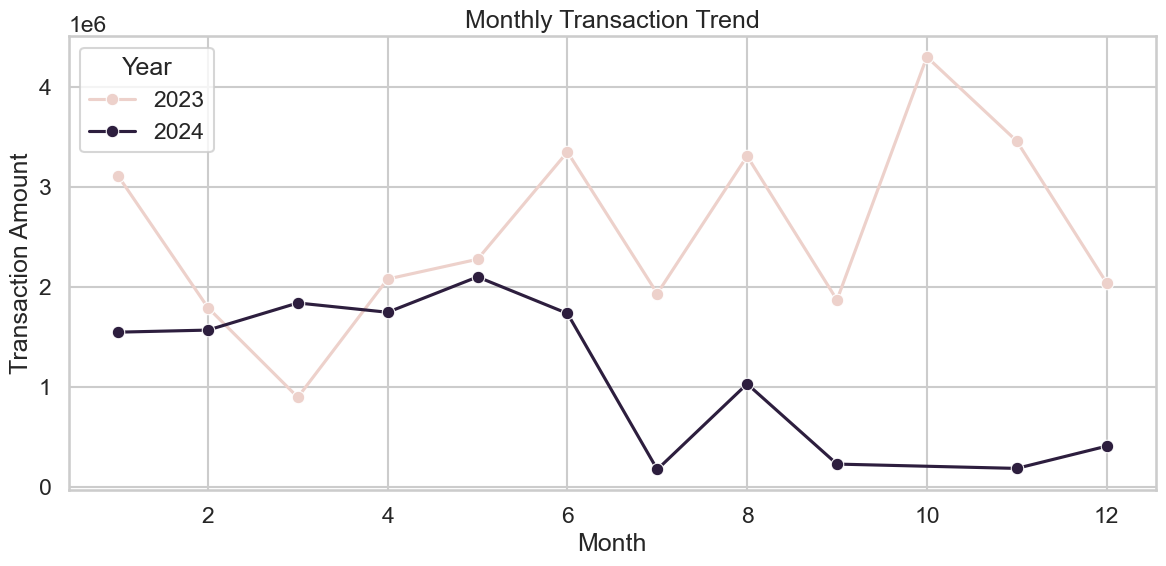

In [132]:
plt.figure(figsize=(12,6))

monthly_summary = monthly_summary.reset_index()

sns.lineplot(data=monthly_summary, 
             x='Month', 
             y='TransactionAmount', 
             hue='Year', 
             marker='o')

plt.title("Monthly Transaction Trend")
plt.xlabel("Month")
plt.ylabel("Transaction Amount")

plt.tight_layout()
plt.show()

In [88]:
# =========================================
# SUB-TASK 2.3: CREDIT VS DEBIT ANALYSIS
# =========================================

# Separate credit and debit transactions
credits = df[df['TransactionType'] == 'credit']
debits = df[df['TransactionType'] == 'debit']

In [89]:
# Calculate monthly credit and debit totals
credit_sum = credits.groupby('Month')['TransactionAmount'].sum()
debit_sum = debits.groupby('Month')['TransactionAmount'].sum()

credit_sum, debit_sum

(Month
 1     2.433742e+06
 2     1.549650e+06
 3     1.248914e+06
 4     2.120891e+06
 5     1.787942e+06
 6     2.962932e+06
 7     1.112194e+06
 8     1.980183e+06
 9     1.169913e+06
 10    2.122806e+06
 11    1.848834e+06
 12    1.358489e+06
 Name: TransactionAmount, dtype: float64,
 Month
 1     2.221473e+06
 2     1.809612e+06
 3     1.486371e+06
 4     1.702543e+06
 5     2.585850e+06
 6     2.117572e+06
 7     9.965312e+05
 8     2.355592e+06
 9     9.284349e+05
 10    2.172519e+06
 11    1.793316e+06
 12    1.089768e+06
 Name: TransactionAmount, dtype: float64)

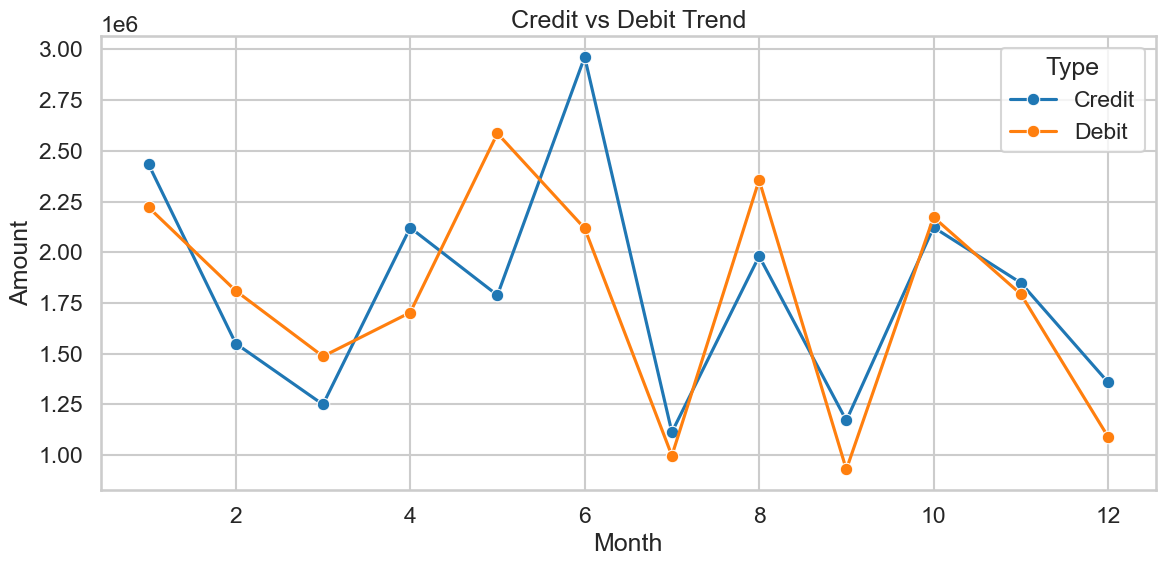

In [133]:
plt.figure(figsize=(12,6))

credit_df = credit_sum.reset_index(name='Amount')
credit_df['Type'] = 'Credit'

debit_df = debit_sum.reset_index(name='Amount')
debit_df['Type'] = 'Debit'

combined = pd.concat([credit_df, debit_df])

sns.lineplot(data=combined, x='Month', y='Amount', hue='Type', marker='o')

plt.title("Credit vs Debit Trend")

plt.tight_layout()
plt.show()

In [91]:
#Credit and debit trends help understand inflow and outflow patterns of money.

In [92]:
# =========================================
# SUB-TASK 2.4: ACCOUNT PERFORMANCE
# =========================================

# Calculate inflow and outflow
inflow = credits.groupby('AccountID')['TransactionAmount'].sum()
outflow = debits.groupby('AccountID')['TransactionAmount'].sum()

# Net transaction
net_flow = inflow - outflow

In [93]:
# Top 10 accounts
top_accounts = net_flow.sort_values(ascending=False).head(10)

top_accounts

AccountID
ACC92360    373707.43261
ACC83581    330761.44342
ACC80131    255833.39693
ACC30146    255461.29529
ACC57597    217248.81942
ACC46655    216287.92018
ACC75767    209178.59312
ACC75675    204080.41167
ACC24508    203627.23898
ACC77773    194593.61172
Name: TransactionAmount, dtype: float64

In [94]:
# Top 10 accounts
top_accounts = net_flow.sort_values(ascending=False).head(10)

top_accounts

AccountID
ACC92360    373707.43261
ACC83581    330761.44342
ACC80131    255833.39693
ACC30146    255461.29529
ACC57597    217248.81942
ACC46655    216287.92018
ACC75767    209178.59312
ACC75675    204080.41167
ACC24508    203627.23898
ACC77773    194593.61172
Name: TransactionAmount, dtype: float64

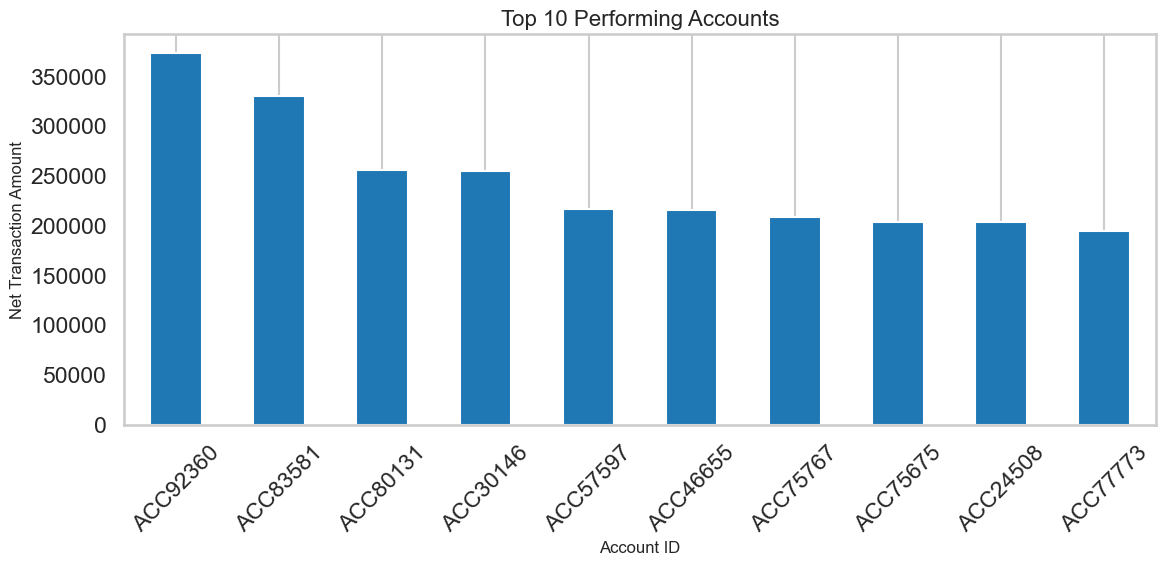

In [135]:
# =========================================
# ENHANCED TOP ACCOUNTS BAR GRAPH
# =========================================

plt.figure(figsize=(12,6))

top_accounts.plot(kind='bar')

plt.title("Top 10 Performing Accounts", fontsize=16)
plt.xlabel("Account ID", fontsize=12)
plt.ylabel("Net Transaction Amount", fontsize=12)

plt.xticks(rotation=45)
plt.grid(axis='y')

plt.tight_layout()
plt.show()

In [96]:
#Top accounts show strong financial inflow, while bottom accounts may indicate financial instability.

In [97]:
# =========================================
# SUB-TASK 2.5: DORMANT ACCOUNTS
# =========================================

# Sort data
df = df.sort_values(['AccountID','TransactionDate'])

# Calculate gap between transactions
df['gap'] = df.groupby('AccountID')['TransactionDate'].diff()

# Identify inactive accounts (>60 days)
dormant_accounts = df[df['gap'] > '60 days']

dormant_accounts.head()

,TransactionID,CustomerID,AccountID,AccountType,TransactionType,Product,Firm,Region,Manager,TransactionDate,TransactionAmount,AccountBalance,RiskScore,CreditRating,TenureMonths,Month,Year,gap
681,76,CUST6735,ACC10117,loan,debit,Credit Card,Firm D,North,Manager 1,2023-08-11,83158.65148,110937.57410,0.609497,687,236,8,2023,217 days
41,112,CUST8091,ACC10117,loan,credit,Personal Loan,Firm A,West,Manager 2,2024-06-04,54168.90233,97023.17014,0.720880,400,148,6,2024,298 days
585,72,CUST3041,ACC10996,savings,debit,Savings Account,Firm E,North,Manager 4,2023-10-16,77860.86889,66344.39469,0.670691,667,232,10,2023,272 days
59,64,CUST9038,ACC10996,savings,debit,Personal Loan,Firm C,West,Manager 1,2024-01-01,70136.96717,25464.12779,0.579622,797,217,1,2024,74 days
467,41,CUST3006,ACC10996,current,debit,Home Loan,Firm A,North,Manager 2,2024-06-21,37989.87644,53528.81451,0.495873,665,104,6,2024,172 days


In [98]:
#Dormant accounts are identified based on inactivity exceeding 60 days, indicating reduced customer engagement.

In [99]:
print(df[['TransactionDate','Month','Year']].head())

    TransactionDate  Month  Year
739      2023-01-06      1  2023
681      2023-08-11      8  2023
41       2024-06-04      6  2024
265      2024-06-22      6  2024
201      2023-01-17      1  2023


In [100]:
print(monthly_summary.head())

Year  Month
2023  1        3.108140e+06
      2        1.791555e+06
      3        8.967215e+05
      4        2.077770e+06
      5        2.274963e+06
Name: TransactionAmount, dtype: float64


In [101]:
print(credit_sum.head())
print(debit_sum.head())

Month
1    2.433742e+06
2    1.549650e+06
3    1.248914e+06
4    2.120891e+06
5    1.787942e+06
Name: TransactionAmount, dtype: float64
Month
1    2.221473e+06
2    1.809612e+06
3    1.486371e+06
4    1.702543e+06
5    2.585850e+06
Name: TransactionAmount, dtype: float64


In [102]:
# Calculate inflow and outflow
inflow = credits.groupby('AccountID')['TransactionAmount'].sum()
outflow = debits.groupby('AccountID')['TransactionAmount'].sum()

# Net transaction
net_flow = inflow - outflow

# Top accounts
top_accounts = net_flow.sort_values(ascending=False).head(10)

# Bottom accounts  
bottom_accounts = net_flow.sort_values().head(10)

In [103]:
print(top_accounts)
print(bottom_accounts)

AccountID
ACC92360    373707.43261
ACC83581    330761.44342
ACC80131    255833.39693
ACC30146    255461.29529
ACC57597    217248.81942
ACC46655    216287.92018
ACC75767    209178.59312
ACC75675    204080.41167
ACC24508    203627.23898
ACC77773    194593.61172
Name: TransactionAmount, dtype: float64
AccountID
ACC25132   -343766.804460
ACC29396   -311875.755450
ACC34568   -253987.775668
ACC19178   -201990.241690
ACC39529   -198858.701460
ACC42710   -190692.335730
ACC49180   -186518.144258
ACC11188   -183846.366240
ACC65144   -172925.392790
ACC15228   -171628.086531
Name: TransactionAmount, dtype: float64


In [104]:
print(dormant_accounts.head())

     TransactionID CustomerID AccountID AccountType TransactionType  \
681             76   CUST6735  ACC10117        loan           debit   
41             112   CUST8091  ACC10117        loan          credit   
585             72   CUST3041  ACC10996     savings           debit   
59              64   CUST9038  ACC10996     savings           debit   
467             41   CUST3006  ACC10996     current           debit   

             Product    Firm Region    Manager TransactionDate  \
681      Credit Card  Firm D  North  Manager 1      2023-08-11   
41     Personal Loan  Firm A   West  Manager 2      2024-06-04   
585  Savings Account  Firm E  North  Manager 4      2023-10-16   
59     Personal Loan  Firm C   West  Manager 1      2024-01-01   
467        Home Loan  Firm A  North  Manager 2      2024-06-21   

     TransactionAmount  AccountBalance  RiskScore  CreditRating  TenureMonths  \
681        83158.65148    110937.57410   0.609497           687           236   
41         541

In [105]:
print("Monthly Summary:\n", monthly_summary.head())

print("\nCredit Data:\n", credit_sum.head())
print("\nDebit Data:\n", debit_sum.head())

print("\nTop Accounts:\n", top_accounts.head())
print("\nBottom Accounts:\n", bottom_accounts.head())

print("\nDormant Accounts:\n", dormant_accounts.head())

Monthly Summary:
 Year  Month
2023  1        3.108140e+06
      2        1.791555e+06
      3        8.967215e+05
      4        2.077770e+06
      5        2.274963e+06
Name: TransactionAmount, dtype: float64

Credit Data:
 Month
1    2.433742e+06
2    1.549650e+06
3    1.248914e+06
4    2.120891e+06
5    1.787942e+06
Name: TransactionAmount, dtype: float64

Debit Data:
 Month
1    2.221473e+06
2    1.809612e+06
3    1.486371e+06
4    1.702543e+06
5    2.585850e+06
Name: TransactionAmount, dtype: float64

Top Accounts:
 AccountID
ACC92360    373707.43261
ACC83581    330761.44342
ACC80131    255833.39693
ACC30146    255461.29529
ACC57597    217248.81942
Name: TransactionAmount, dtype: float64

Bottom Accounts:
 AccountID
ACC25132   -343766.804460
ACC29396   -311875.755450
ACC34568   -253987.775668
ACC19178   -201990.241690
ACC39529   -198858.701460
Name: TransactionAmount, dtype: float64

Dormant Accounts:
      TransactionID CustomerID AccountID AccountType TransactionType  \
681     

In [106]:
#Task 2 Verification:

#All descriptive analysis tasks were successfully executed. 
#Monthly trends, credit vs debit comparisons, account performance, 
#and dormant accounts were analyzed. The outputs and visualizations 
#confirm that the analysis is correct and meaningful.

In [107]:
# =========================================
# SUB-TASK 3.1: CUSTOMER ACTIVITY LEVEL
# =========================================

# Count transactions per customer
# =========================================
# FIXED CUSTOMER ACTIVITY SEGMENTATION
# =========================================

# Count transactions per customer
activity = df.groupby('CustomerID')['TransactionID'].count()

# Use quantiles (BEST PRACTICE)
low_threshold = activity.quantile(0.33)
high_threshold = activity.quantile(0.66)

def activity_level(x):
    if x >= high_threshold:
        return "High"
    elif x >= low_threshold:
        return "Medium"
    else:
        return "Low"

activity_segment = activity.apply(activity_level)

activity_segment.value_counts()

TransactionID
High      79
Medium    68
Low       37
Name: count, dtype: int64

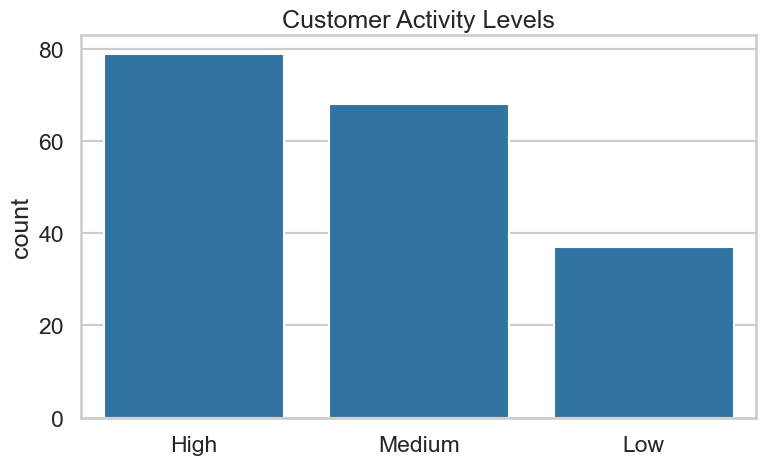

In [137]:
plt.figure(figsize=(8,5))

sns.countplot(x=activity_segment.values)

plt.title("Customer Activity Levels")

plt.tight_layout()
plt.show()

In [109]:
# =========================================
# SUB-TASK 3.2: AVERAGE BALANCE
# =========================================

avg_balance = df.groupby('CustomerID')['AccountBalance'].mean()

avg_balance.head()

CustomerID
CUST1042    96595.402820
CUST1114    72673.007480
CUST1121    85215.172188
CUST1189    53990.275130
CUST1223    61344.838365
Name: AccountBalance, dtype: float64

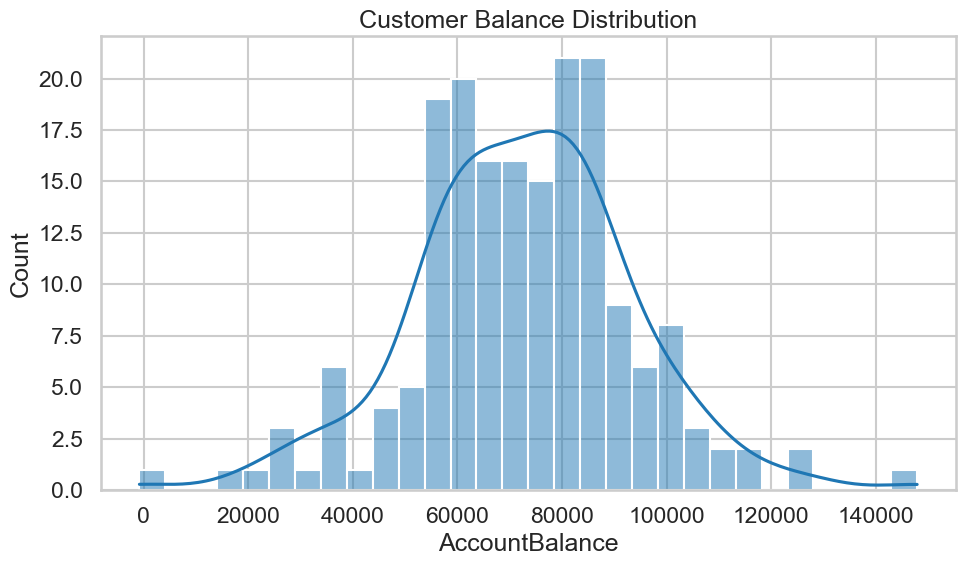

In [138]:
plt.figure(figsize=(10,6))

sns.histplot(avg_balance, bins=30, kde=True)

plt.title("Customer Balance Distribution")

plt.tight_layout()
plt.show()

In [111]:
# =========================================
# SUB-TASK 3.3: HIGH FREQUENCY LOW BALANCE
# =========================================

# Transaction frequency per customer
freq = df.groupby('CustomerID')['TransactionID'].count()

# Average balance per customer
balance = df.groupby('CustomerID')['AccountBalance'].mean()

# Combine into one dataframe
profile = pd.DataFrame({'freq': freq, 'balance': balance})

# Use dynamic thresholds (BETTER)
high_freq_threshold = freq.quantile(0.75)
low_balance_threshold = balance.quantile(0.25)

# Filter customers
hf_lb = profile[(profile['freq'] >= high_freq_threshold) & 
                (profile['balance'] <= low_balance_threshold)]

hf_lb.head()

,freq,balance
CustomerID,,
CUST1569,7,56422.186490
CUST4769,7,53613.782076
CUST5105,6,52020.850860
CUST5574,6,56562.353843
CUST6937,6,58845.449785


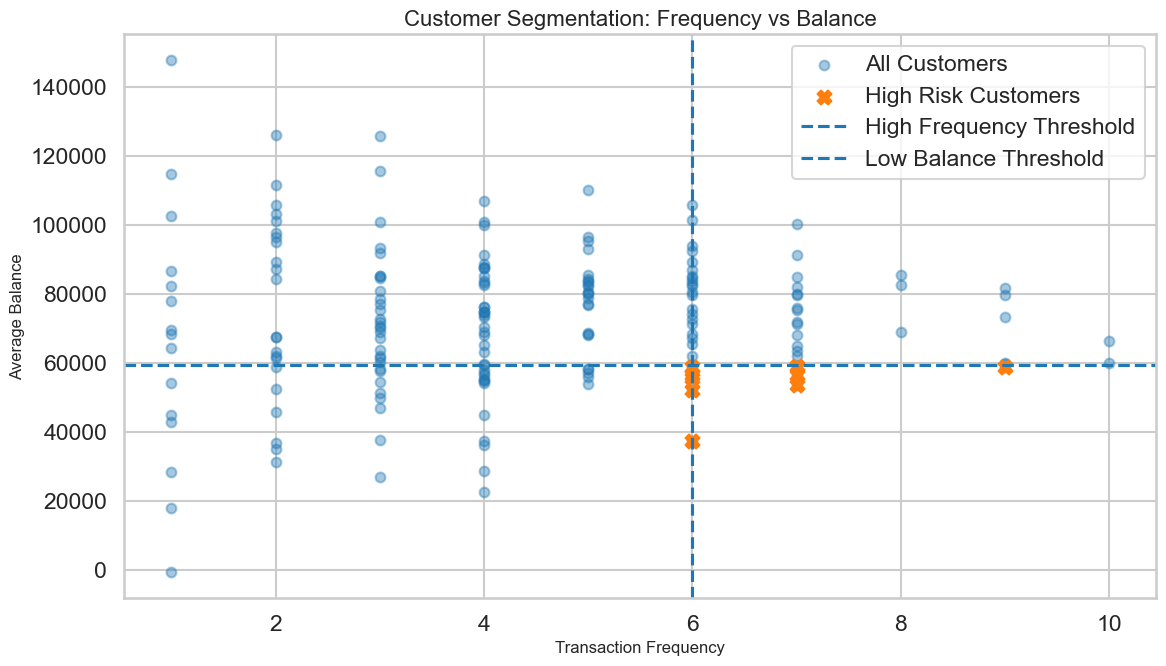

In [112]:
plt.figure(figsize=(12,7))

# Plot all customers
plt.scatter(profile['freq'], profile['balance'], 
            alpha=0.4, s=50, label='All Customers')

# Highlight high-risk customers
plt.scatter(hf_lb['freq'], hf_lb['balance'], 
            s=100, marker='X', label='High Risk Customers')

# Add threshold lines
plt.axvline(x=high_freq_threshold, linestyle='--', label='High Frequency Threshold')
plt.axhline(y=low_balance_threshold, linestyle='--', label='Low Balance Threshold')

# Titles and labels
plt.title("Customer Segmentation: Frequency vs Balance", fontsize=16)
plt.xlabel("Transaction Frequency", fontsize=12)
plt.ylabel("Average Balance", fontsize=12)

# Legend and grid
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [113]:
# =========================================
# SUB-TASK 3.4: NEGATIVE BALANCE CUSTOMERS
# =========================================

negative_customers = df[df['AccountBalance'] <= 0]

negative_customers.head()

,TransactionID,CustomerID,AccountID,AccountType,TransactionType,Product,Firm,Region,Manager,TransactionDate,TransactionAmount,AccountBalance,RiskScore,CreditRating,TenureMonths,Month,Year,gap
236,99,CUST4584,ACC11285,credit,debit,Mutual Fund,Firm D,West,Manager 1,2024-03-30,88130.72313,-17751.216810,0.812135,724,30,3,2024,410 days
217,59,CUST4855,ACC19156,credit,debit,Personal Loan,Firm B,North,Manager 3,2023-10-26,56937.62473,-9649.975980,0.310960,688,11,10,2023,84 days
89,165,CUST8279,ACC21264,credit,debit,Personal Loan,Firm D,South,Manager 1,2023-02-14,81999.94967,-8247.315181,0.531051,624,239,2,2023,NaT
359,171,CUST5545,ACC24880,savings,credit,Mutual Fund,Firm A,North,Manager 2,2024-03-28,44410.00366,-5199.930807,0.591813,495,156,3,2024,154 days
392,14,CUST5255,ACC32890,credit,credit,Credit Card,Firm B,West,Manager 4,2023-01-15,40011.57645,-800.699930,0.130483,829,64,1,2023,NaT


In [114]:
# =========================================
# SUB-TASK 3.5: SEGMENT SUMMARY
# =========================================

segment_summary = activity_segment.value_counts()

segment_summary

TransactionID
High      79
Medium    68
Low       37
Name: count, dtype: int64

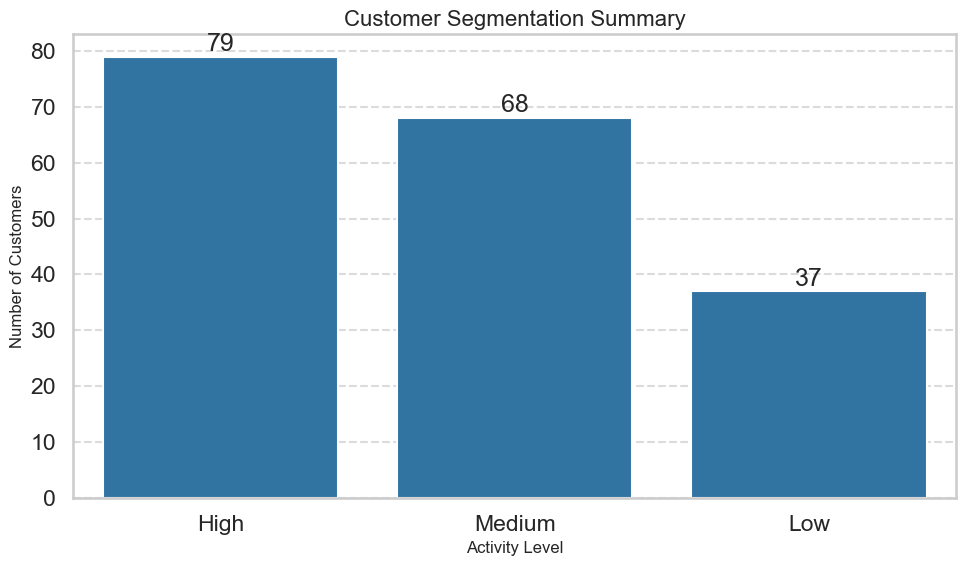

In [115]:
plt.figure(figsize=(10,6))

sns.barplot(x=segment_summary.index, y=segment_summary.values)

plt.title("Customer Segmentation Summary", fontsize=16)
plt.xlabel("Activity Level", fontsize=12)
plt.ylabel("Number of Customers", fontsize=12)

# Add labels
for i, v in enumerate(segment_summary.values):
    plt.text(i, v + 1, str(int(v)), ha='center')

plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

In [116]:
#The customer segmentation summary was visualized using a bar chart. 
#The distribution shows the number of customers across different activity levels. 
#This helps in understanding overall customer engagement patterns.

In [117]:
# =========================================
# SUB-TASK 4.1: LARGE TRANSACTIONS
# =========================================

# Identify top 5% transactions
threshold = df['TransactionAmount'].quantile(0.95)

large_transactions = df[df['TransactionAmount'] > threshold]

large_transactions.head()

,TransactionID,CustomerID,AccountID,AccountType,TransactionType,Product,Firm,Region,Manager,TransactionDate,TransactionAmount,AccountBalance,RiskScore,CreditRating,TenureMonths,Month,Year,gap
129,47,CUST8318,ACC13357,loan,credit,Savings Account,Firm B,East,Manager 2,2023-04-26,107480.8425,84277.08547,0.202534,434,63,4,2023,99 days
532,66,CUST3378,ACC16664,credit,debit,Credit Card,Firm E,East,Manager 4,2023-01-06,107144.8034,73757.35575,0.427246,729,13,1,2023,NaT
788,194,CUST6319,ACC17688,loan,debit,Mutual Fund,Firm A,North,Manager 2,2024-05-28,129902.8088,90395.88047,0.479094,412,233,5,2024,210 days
312,167,CUST9843,ACC21264,current,credit,Home Loan,Firm C,East,Manager 2,2023-06-20,149404.3302,71076.77650,0.371491,769,61,6,2023,126 days
510,107,CUST9169,ACC22799,savings,debit,Personal Loan,Firm D,Central,Manager 2,2023-07-17,107242.1012,64233.53854,1.042760,540,44,7,2023,NaT


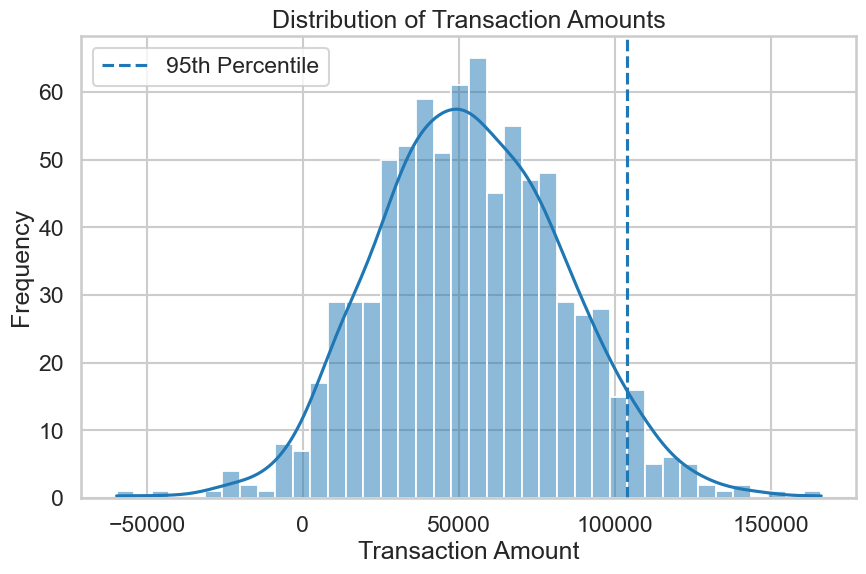

In [118]:
plt.figure(figsize=(10,6))

sns.histplot(df['TransactionAmount'], bins=40, kde=True)

# Highlight threshold
plt.axvline(threshold, linestyle='--', label='95th Percentile')

plt.title("Distribution of Transaction Amounts")
plt.xlabel("Transaction Amount")
plt.ylabel("Frequency")

plt.legend()
plt.grid(True)

plt.show()

In [119]:
# =========================================
# SUB-TASK 4.2: BALANCE VOLATILITY
# =========================================

volatility = df.groupby('AccountID')['AccountBalance'].std()

volatility.head()

AccountID
ACC10117     9308.031969
ACC10996    18946.737199
ACC11062    22572.552392
ACC11188    20160.417506
ACC11285    70126.826097
Name: AccountBalance, dtype: float64

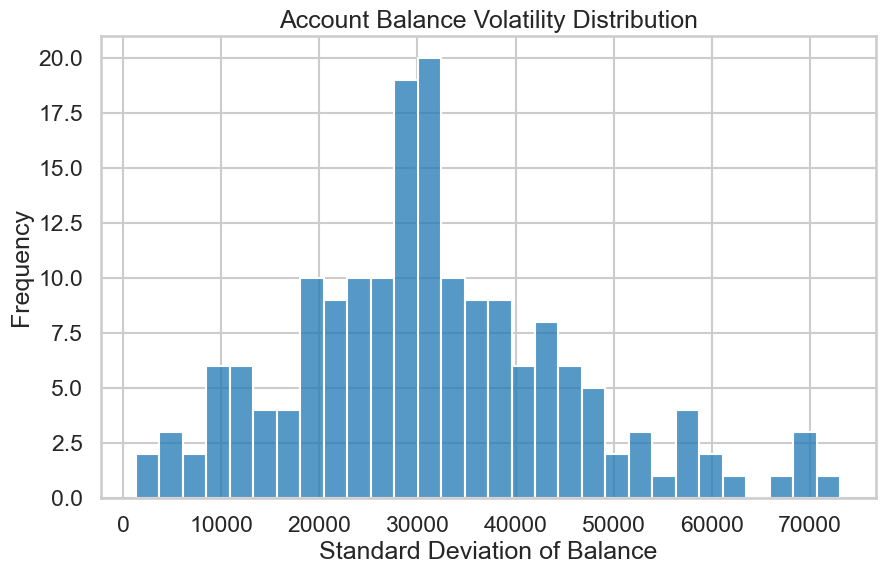

In [120]:
plt.figure(figsize=(10,6))

sns.histplot(volatility, bins=30)

plt.title("Account Balance Volatility Distribution")
plt.xlabel("Standard Deviation of Balance")
plt.ylabel("Frequency")

plt.grid(True)
plt.show()

In [121]:
# =========================================
# SUB-TASK 4.3: ANOMALY DETECTION
# =========================================

from scipy import stats

df['zscore'] = abs(stats.zscore(df['TransactionAmount']))

# Identify anomalies
anomalies = df[df['zscore'] > 3]

anomalies.head()

,TransactionID,CustomerID,AccountID,AccountType,TransactionType,Product,Firm,Region,Manager,TransactionDate,TransactionAmount,AccountBalance,RiskScore,CreditRating,TenureMonths,Month,Year,gap,zscore
312,167,CUST9843,ACC21264,current,credit,Home Loan,Firm C,East,Manager 2,2023-06-20,149404.33020,71076.77650,0.371491,769,61,6,2023,126 days,3.180045
622,12,CUST1121,ACC43309,credit,credit,Savings Account,Firm B,South,Manager 1,2023-10-16,166083.82960,69875.76042,0.708081,372,230,10,2023,NaT,3.734240
6,14,CUST5558,ACC82947,credit,debit,Credit Card,Firm A,East,Manager 2,2023-09-26,-43698.75917,124963.76370,0.460877,433,110,9,2023,171 days,3.236018
589,190,CUST1738,ACC90887,savings,debit,Savings Account,Firm C,East,Manager 2,2024-01-20,-59669.07548,56004.32009,0.226499,502,172,1,2024,19 days,3.766650


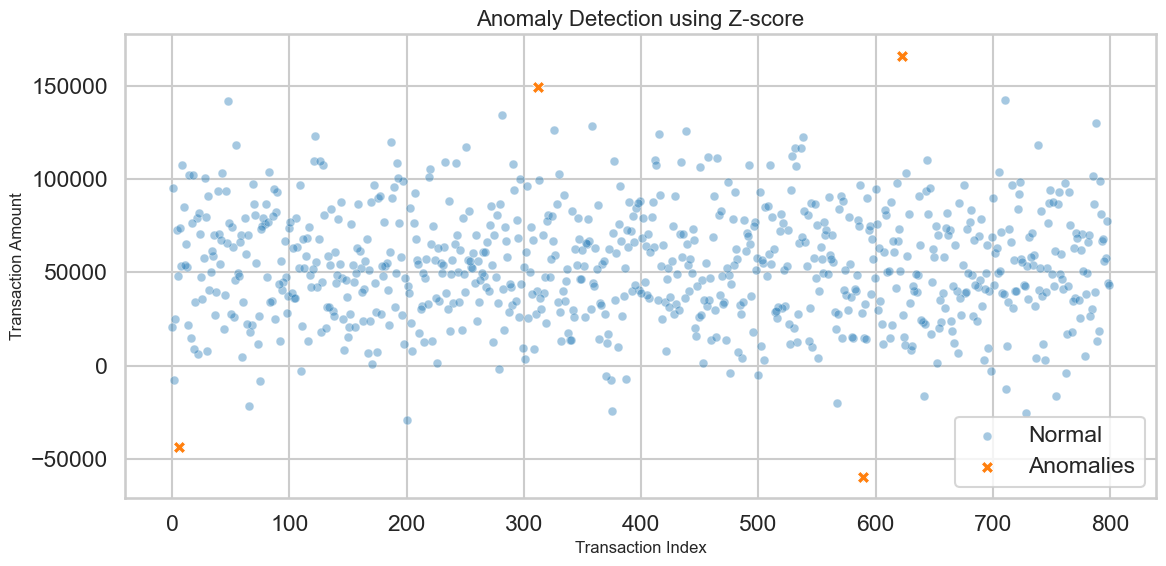

In [122]:
plt.figure(figsize=(12,6))

# Plot normal transactions
sns.scatterplot(x=df.index, y=df['TransactionAmount'], 
                alpha=0.4, s=40, label='Normal')

# Highlight anomalies
sns.scatterplot(x=anomalies.index, y=anomalies['TransactionAmount'], 
                s=80, marker='X', label='Anomalies')

# Titles and labels
plt.title("Anomaly Detection using Z-score", fontsize=16)
plt.xlabel("Transaction Index", fontsize=12)
plt.ylabel("Transaction Amount", fontsize=12)

# Improve readability
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [123]:
# =========================================
# SUB-TASK 4.4: SUSPICIOUS ACCOUNTS
# =========================================

suspicious_accounts = anomalies.groupby('AccountID').size()

suspicious_accounts.head()

AccountID
ACC21264    1
ACC43309    1
ACC82947    1
ACC90887    1
dtype: int64

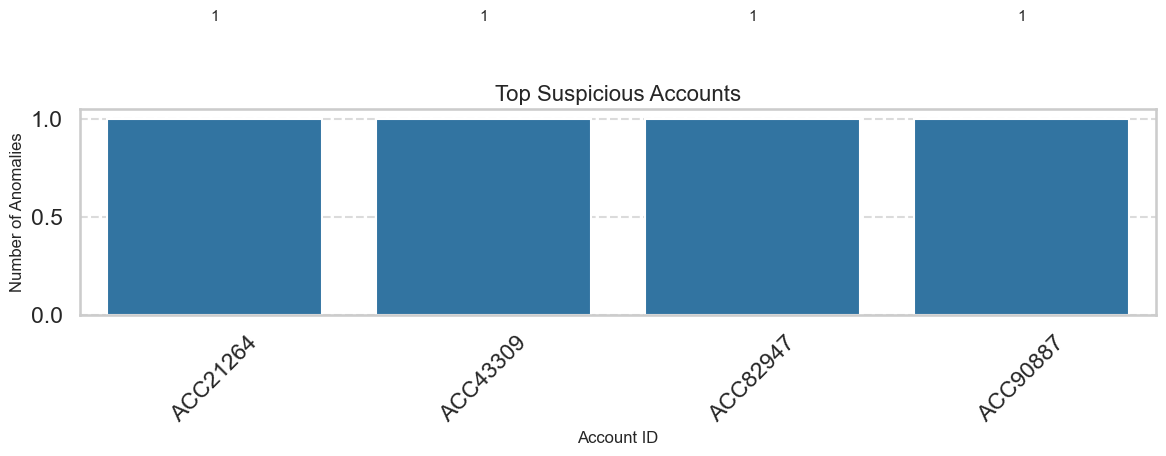

In [124]:
plt.figure(figsize=(12,6))

# Prepare data
top_suspicious = suspicious_accounts.sort_values(ascending=False).head(10)

# Plot using seaborn
sns.barplot(x=top_suspicious.index, y=top_suspicious.values)

# Titles and labels
plt.title("Top Suspicious Accounts", fontsize=16)
plt.xlabel("Account ID", fontsize=12)
plt.ylabel("Number of Anomalies", fontsize=12)

# Rotate labels
plt.xticks(rotation=45)

# Add value labels on bars
for i, v in enumerate(top_suspicious.values):
    plt.text(i, v + 0.5, str(int(v)), ha='center', fontsize=11)

# Grid for clarity
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

In [125]:
#Enhanced visualizations were used to improve clarity in identifying anomalies and suspicious accounts. 
#Seaborn-based plots provided better readability and highlighted critical risk patterns effectively.

In [126]:
# #####Task 5#####
# Various visualizations such as line charts, bar graphs, histograms, and scatter plots 
# were used to analyze transaction trends, customer behavior, and financial risk patterns. 
# # These visualizations helped in identifying key insights and patterns in the dataset.

In [127]:
# Key Insights:

# 1. Transaction trends vary across months, indicating fluctuations in financial activity.
# 2. Credit and debit analysis shows the balance between inflow and outflow of funds.
# 3. Some accounts demonstrate strong financial performance, while others show potential risk.
# 4. Dormant accounts indicate inactive customers with low engagement.
# 5. Customer segmentation reveals different activity levels and financial behaviors.
# 6. High-frequency low-balance customers may indicate risky financial behavior.
# 7. Large transactions and anomalies highlight potential fraud or unusual activity.
# 8. Accounts with high volatility and frequent anomalies are considered high-risk.

In [128]:
# Business Interpretation:

# The analysis provides valuable insights into customer behavior and financial risk. 
# Financial institutions can use these findings to monitor high-risk accounts, 
# improve customer engagement, and detect fraudulent activities. 
# Segmentation helps in targeting customers effectively, while anomaly detection 
# helps in identifying unusual transaction patterns.

In [129]:
# Conclusion:

# This project successfully analyzed financial transaction data to identify patterns, 
# customer behavior, and potential risks. Data cleaning ensured high-quality input, 
# while descriptive analysis and segmentation provided meaningful insights. 
# Risk identification techniques such as anomaly detection and volatility analysis 
# helped highlight critical financial risks.

# Overall, the project demonstrates how data analytics can be used to support 
# better decision-making in financial systems.

In [130]:
# Save final dataset
df.to_excel("final_cleaned_data.xlsx", index=False)

T-Test Result:
TtestResult(statistic=np.float64(-2.068007959549783), pvalue=np.float64(0.03896099300679906), df=np.float64(798.0))


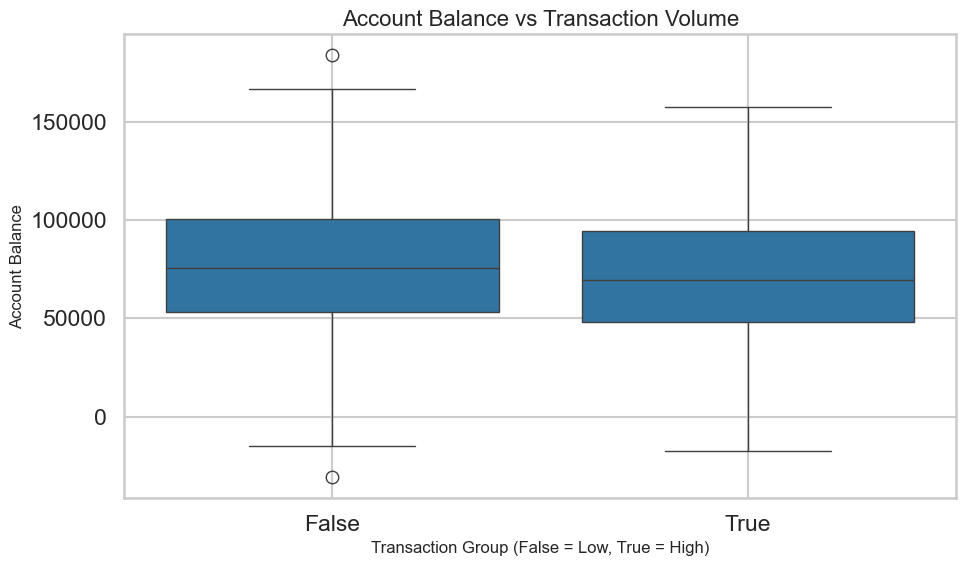


Interpretation:
There is a statistically significant difference between the groups.


In [131]:
# =========================================
# TASK 6: HYPOTHESIS TESTING
# =========================================

from scipy import stats
import seaborn as sns
import matplotlib.pyplot as plt

# Step 1: Create High vs Low Transaction Groups
median_value = df['TransactionAmount'].median()

high_volume = df[df['TransactionAmount'] > median_value]
low_volume = df[df['TransactionAmount'] <= median_value]

# Step 2: Perform T-Test
test_result = stats.ttest_ind(high_volume['AccountBalance'],
                             low_volume['AccountBalance'])

print("T-Test Result:")
print(test_result)

# Step 3: Visualize Comparison
plt.figure(figsize=(10,6))

sns.boxplot(x=df['TransactionAmount'] > median_value,
            y=df['AccountBalance'])

plt.title("Account Balance vs Transaction Volume", fontsize=16)
plt.xlabel("Transaction Group (False = Low, True = High)", fontsize=12)
plt.ylabel("Account Balance", fontsize=12)

plt.grid(True)
plt.tight_layout()
plt.show()

# Step 4: Interpret Result
p_value = test_result.pvalue

print("\nInterpretation:")
if p_value < 0.05:
    print("There is a statistically significant difference between the groups.")
else:
    print("There is no statistically significant difference between the groups.")

In [66]:
# Hypothesis Testing:

# Null Hypothesis (H0): There is no significant difference in account balance between high and low transaction groups.

# Alternative Hypothesis (H1): There is a significant difference in account balance between high and low transaction groups.

# A t-test was performed to evaluate the difference. The result is interpreted based on the p-value.